<a href="https://colab.research.google.com/github/allusaatvikacs24-collab/AI_LAB/blob/main/1BF24CS037_Week7_ForwardChaining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Starting Forward Reasoning...
Initial Facts: {('Owns', ('A', 'T1')), ('American', ('Robert',)), ('Missile', ('T1',)), ('Enemy', ('A', 'America'))}

Step 1: Applied rule [('Missile', ('x',))] => ('Weapon', ('x',)) with {'x': 'T1'}
Added Fact: ('Weapon', ('T1',))

Step 2: Applied rule [('Missile', ('x',)), ('Owns', ('A', 'x'))] => ('Sells', ('Robert', 'x', 'A')) with {'x': 'T1'}
Added Fact: ('Sells', ('Robert', 'T1', 'A'))

Step 3: Applied rule [('Enemy', ('x', 'America'))] => ('Hostile', ('x',)) with {'x': 'A'}
Added Fact: ('Hostile', ('A',))

Step 4: Applied rule [('American', ('p',)), ('Weapon', ('q',)), ('Sells', ('p', 'q', 'r')), ('Hostile', ('r',))] => ('Criminal', ('p',)) with {'p': 'Robert', 'q': 'T1', 'r': 'A'}
Added Fact: ('Criminal', ('Robert',))

Query ('Criminal', ('Robert',)) PROVED successfully!



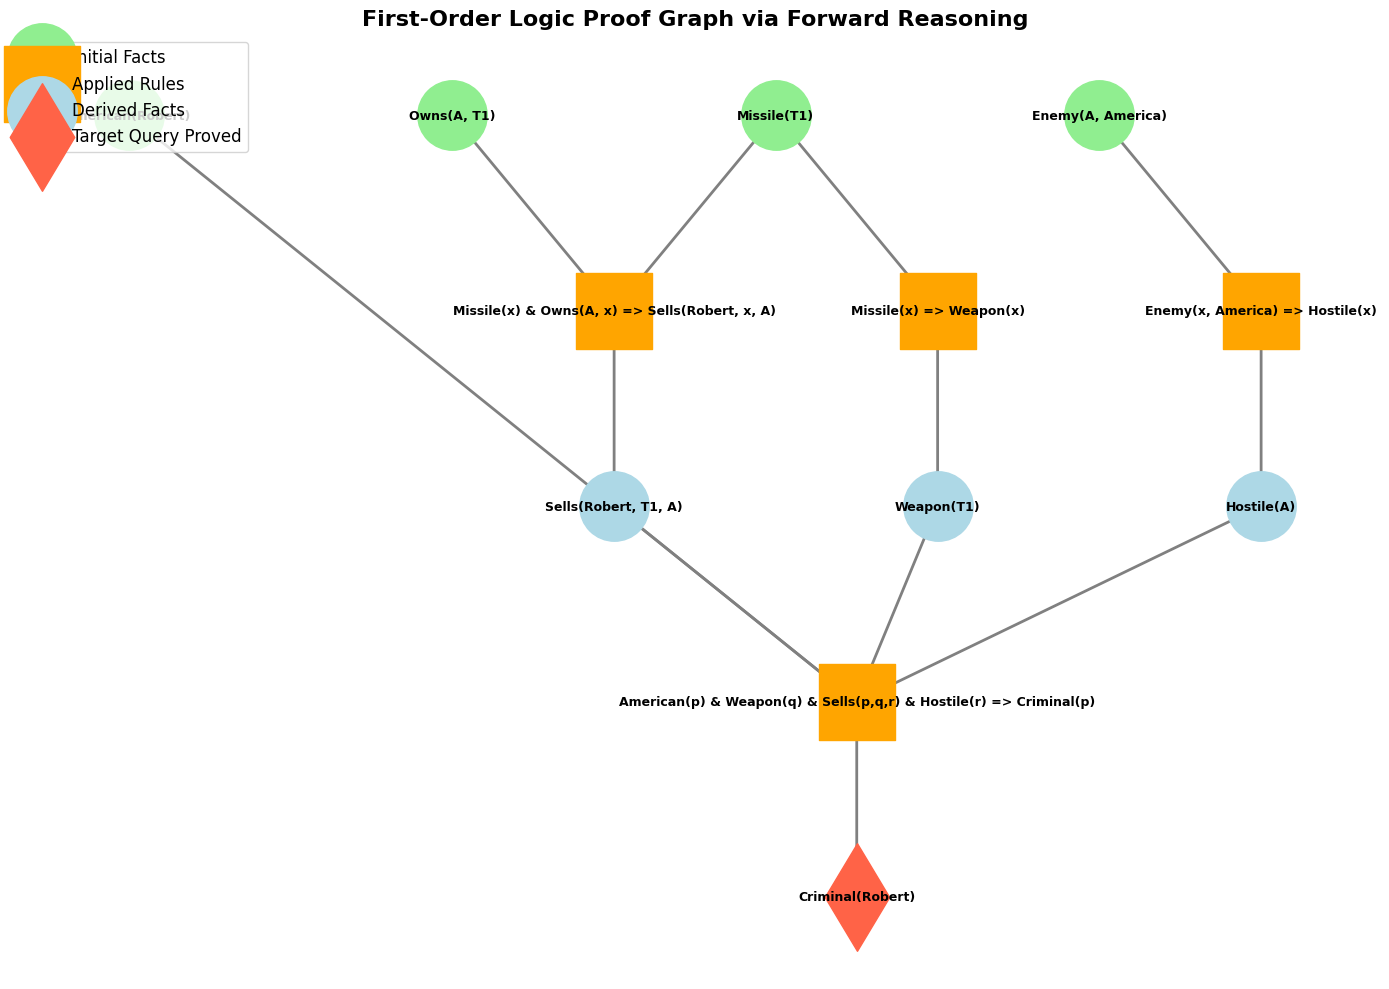

In [5]:
import networkx as nx
import matplotlib.pyplot as plt

class FOLKnowledgeBase:
    def __init__(self):
        self.facts = set()
        self.rules = []

    def add_fact(self, predicate, *args):
        self.facts.add((predicate, tuple(args)))

    def add_rule(self, premises, conclusion):
        self.rules.append((premises, conclusion))

    def is_variable(self, x):
        return isinstance(x, str) and x.islower() and len(x) == 1

    def match(self, pattern, fact, theta):
        if len(pattern[1]) != len(fact[1]) or pattern[0] != fact[0]:
            return None

        new_theta = theta.copy()
        for p_arg, f_arg in zip(pattern[1], fact[1]):
            if self.is_variable(p_arg):
                if p_arg in new_theta:
                    if new_theta[p_arg] != f_arg:
                        return None
                else:
                    new_theta[p_arg] = f_arg
            else:
                if p_arg != f_arg:
                    return None
        return new_theta

    def find_substitutions(self, premises, theta):
        if not premises:
            return [theta]

        first, rest = premises[0], premises[1:]
        substitutions = []

        for fact in self.facts:
            new_theta = self.match(first, fact, theta)
            if new_theta is not None:
                substitutions.extend(self.find_substitutions(rest, new_theta))

        return substitutions

    def forward_reasoning(self, query):
        print("Starting Forward Reasoning...")
        print(f"Initial Facts: {self.facts}\n")

        query_pred, query_args = query

        if (query_pred, tuple(query_args)) in self.facts:
            print(f"Query {query} is already a known fact!")
            return True

        new_facts_added = True
        step = 1

        while new_facts_added:
            new_facts_added = False
            for premises, conclusion in self.rules:
                substitutions = self.find_substitutions(premises, {})

                for theta in substitutions:
                    concl_pred, concl_args = conclusion
                    sub_args = tuple(theta.get(arg, arg) for arg in concl_args)
                    new_fact = (concl_pred, sub_args)

                    if new_fact not in self.facts:
                        self.facts.add(new_fact)
                        print(f"Step {step}: Applied rule {premises} => {conclusion} with {theta}")
                        print(f"Added Fact: {new_fact}\n")
                        new_facts_added = True
                        step += 1

                        if new_fact == (query_pred, tuple(query_args)):
                            print(f"Query {query} PROVED successfully!\n")
                            return True

        print(f"Query {query} could NOT be proved.\n")
        return False

kb_robert = FOLKnowledgeBase()

kb_robert.add_fact('American', 'Robert')
kb_robert.add_fact('Enemy', 'A', 'America')
kb_robert.add_fact('Owns', 'A', 'T1')
kb_robert.add_fact('Missile', 'T1')

kb_robert.add_rule([('Missile', ('x',))], ('Weapon', ('x',)))
kb_robert.add_rule([
    ('Missile', ('x',)),
    ('Owns', ('A', 'x'))
], ('Sells', ('Robert', 'x', 'A')))

kb_robert.add_rule([('Enemy', ('x', 'America'))], ('Hostile', ('x',)))

kb_robert.add_rule([
    ('American', ('p',)),
    ('Weapon', ('q',)),
    ('Sells', ('p', 'q', 'r')),
    ('Hostile', ('r',))
], ('Criminal', ('p',)))

query_robert = ('Criminal', ('Robert',))
kb_robert.forward_reasoning(query_robert)
G = nx.DiGraph()

initial_facts = ["American(Robert)", "Owns(A, T1)", "Missile(T1)", "Enemy(A, America)"]
derived_facts = ["Weapon(T1)", "Sells(Robert, T1, A)", "Hostile(A)", "Criminal(Robert)"]
rules = [
    "Missile(x) => Weapon(x)",
    "Missile(x) & Owns(A, x) => Sells(Robert, x, A)",
    "Enemy(x, America) => Hostile(x)",
    "American(p) & Weapon(q) & Sells(p,q,r) & Hostile(r) => Criminal(p)"
]

for node in initial_facts + derived_facts + rules:
    G.add_node(node)

G.add_edge("Missile(T1)", "Missile(x) => Weapon(x)")
G.add_edge("Missile(x) => Weapon(x)", "Weapon(T1)")

G.add_edge("Missile(T1)", "Missile(x) & Owns(A, x) => Sells(Robert, x, A)")
G.add_edge("Owns(A, T1)", "Missile(x) & Owns(A, x) => Sells(Robert, x, A)")
G.add_edge("Missile(x) & Owns(A, x) => Sells(Robert, x, A)", "Sells(Robert, T1, A)")

G.add_edge("Enemy(A, America)", "Enemy(x, America) => Hostile(x)")
G.add_edge("Enemy(x, America) => Hostile(x)", "Hostile(A)")

G.add_edge("American(Robert)", "American(p) & Weapon(q) & Sells(p,q,r) & Hostile(r) => Criminal(p)")
G.add_edge("Weapon(T1)", "American(p) & Weapon(q) & Sells(p,q,r) & Hostile(r) => Criminal(p)")
G.add_edge("Sells(Robert, T1, A)", "American(p) & Weapon(q) & Sells(p,q,r) & Hostile(r) => Criminal(p)")
G.add_edge("Hostile(A)", "American(p) & Weapon(q) & Sells(p,q,r) & Hostile(r) => Criminal(p)")
G.add_edge("American(p) & Weapon(q) & Sells(p,q,r) & Hostile(r) => Criminal(p)", "Criminal(Robert)")

pos = {
    "American(Robert)": (-3, 3),
    "Owns(A, T1)": (-1, 3),
    "Missile(T1)": (1, 3),
    "Enemy(A, America)": (3, 3),

    "Missile(x) => Weapon(x)": (2, 2),
    "Missile(x) & Owns(A, x) => Sells(Robert, x, A)": (0, 2),
    "Enemy(x, America) => Hostile(x)": (4, 2),

    "Weapon(T1)": (2, 1),
    "Sells(Robert, T1, A)": (0, 1),
    "Hostile(A)": (4, 1),

    "American(p) & Weapon(q) & Sells(p,q,r) & Hostile(r) => Criminal(p)": (1.5, 0),
    "Criminal(Robert)": (1.5, -1)
}

plt.figure(figsize=(14, 10))

nx.draw_networkx_nodes(G, pos, nodelist=initial_facts, node_color='lightgreen', node_shape='o', node_size=2500, label="Initial Facts")
nx.draw_networkx_nodes(G, pos, nodelist=rules, node_color='orange', node_shape='s', node_size=3000, label="Applied Rules")
nx.draw_networkx_nodes(G, pos, nodelist=[df for df in derived_facts if df != "Criminal(Robert)"], node_color='lightblue', node_shape='o', node_size=2500, label="Derived Facts")
nx.draw_networkx_nodes(G, pos, nodelist=["Criminal(Robert)"], node_color='tomato', node_shape='d', node_size=3000, label="Target Query Proved")

# Draw lines and connection labels
nx.draw_networkx_edges(G, pos, arrowstyle="->", arrowsize=20, edge_color="gray", width=2)
nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold")

plt.title("First-Order Logic Proof Graph via Forward Reasoning", fontsize=16, fontweight="bold")
plt.axis('off')
plt.legend(scatterpoints=1, loc="upper left", fontsize=12)
plt.tight_layout()
plt.show()